In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from pygraphon.graphons import StepGraphon
from pygraphon.estimators import SmoothNetHist

from utils_generators import AssociativeFullyRandom
from pygraphon.norm import MseProbaEdge, MaeProbaEdge, AUCEdge, AUPRCEdge
import matplotlib.pyplot as plt
from pygraphon.plots.plot_matrices import spy


# Initialisation

In [3]:
n = 100
k = 2
theta_intra_min, theta_intra_max = 0.5, 0.7
theta_inter_min, theta_inter_max = 0.05, 0.2
theta = AssociativeFullyRandom(
                    K=k,
                    min_inside_classes=theta_intra_min,
                    max_inside_classes=theta_intra_max,
                    min_outside_classes=theta_inter_min,
                    max_outside_classes=theta_inter_max,
                )
print(theta.Theta)
graphon = StepGraphon(theta.Theta, bandwidthHist=1 / k)
adjacency_matrix = graphon.draw(n=n, exchangeable=False)

[[0.56406104 0.10929365]
 [0.10929365 0.69963577]]


# Olhede fit

In [4]:
est = SmoothNetHist()
first_hist_olhede = est._first_approximate_graphon_from_adjacency(adjacencyMatrix= adjacency_matrix)

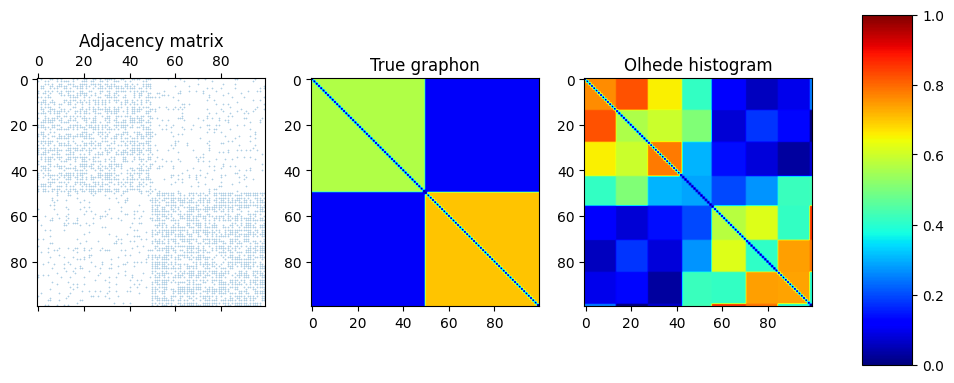

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(first_hist_olhede[0].get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.show()

Edge density:  0.6628571428571428
Edge density:  0.5640816326530612
Edge density:  0.11959183673469388


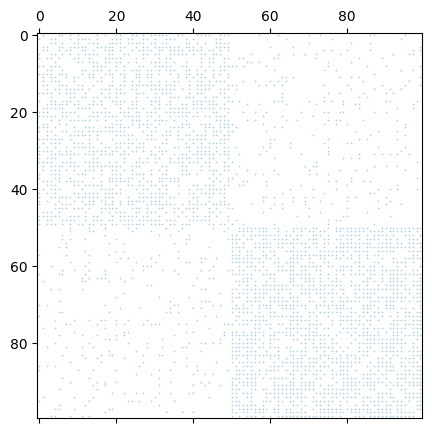

In [6]:
from pygraphon.utils import edge_density
spy(adjacency_matrix)
print("Edge density: ", edge_density(adjacency_matrix[int(n/2):, int(n/2):]))
print("Edge density: ", edge_density(adjacency_matrix[:int(n/2), :int(n/2)]))
print("Edge density: ", edge_density(adjacency_matrix[:int(n/2), int(n/2):]))

# Smooth NetHist fit 

In [7]:
my_est = SmoothNetHist()
my_est.fit(adjacency_matrix)

In [8]:
my_est._first_fit_graphon

In [9]:
print("Ratio of parameters:", my_est.get_ratio_par())
print("Number of unique parameters in SmoothNetHist:", len(np.unique(my_est.graphon.get_graphon())))
print("Number of unique parameters in Olhede:", len(np.unique(first_hist_olhede[0].get_graphon())))


Ratio of parameters: 0.19444444444444445
Number of unique parameters in SmoothNetHist: 7
Number of unique parameters in Olhede: 34


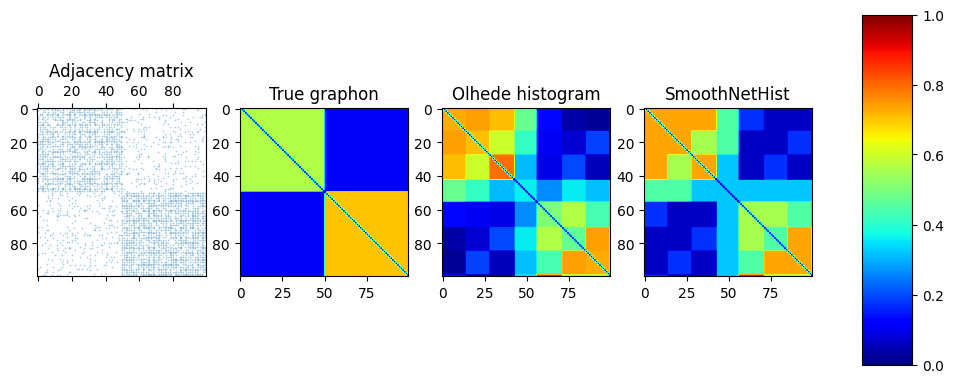

In [10]:
fig, ax = plt.subplots(1, 4, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(my_est._first_fit_graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im3 = ax[3].imshow(my_est.graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
ax[3].set_title("SmoothNetHist")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.colorbar(im3, cax=cbar_ax)
plt.show()

In [11]:
my_est._first_fit_graphon

In [12]:
norm_olhede_mse = MseProbaEdge(n_nodes=n)(graphon, my_est._first_fit_graphon)
norm_olhede_mae = MaeProbaEdge(n_nodes=n)(graphon, my_est._first_fit_graphon)
norm_olhede_auc = AUCEdge(n_nodes=n)(adjacency_matrix, my_est._first_fit_graphon.get_edge_probabilities(n,False,True))
norm_olhede_auprc = AUPRCEdge(n_nodes=n)(adjacency_matrix, my_est._first_fit_graphon.get_edge_probabilities(n,False,True))

norm_smoothnet_mse = MseProbaEdge(n_nodes=n)(graphon, my_est.graphon)
norm_smoothnet_mae = MaeProbaEdge(n_nodes=n)(graphon, my_est.graphon)
norm_smoothnet_auc = AUCEdge(n_nodes=n)(adjacency_matrix, my_est.graphon.get_edge_probabilities(n,False,True))
norm_smoothnet_auprc = AUPRCEdge(n_nodes=n)(adjacency_matrix, my_est.graphon.get_edge_probabilities(n,False,True))

print("MSE Olhede vs SmoothNetHist:", norm_olhede_mse, norm_smoothnet_mse)
print("MAE Olhede vs SmoothNetHist:", norm_olhede_mae, norm_smoothnet_mae)
print("AUC Olhede vs SmoothNetHist:", norm_olhede_auc, norm_smoothnet_auc)
print("AUPRC Olhede vs SmoothNetHist:", norm_olhede_auprc, norm_smoothnet_auprc)

MSE Olhede vs SmoothNetHist: 0.029630849703642822 0.02855307064754858
MAE Olhede vs SmoothNetHist: 0.1360940333184312 0.13492934762140063
AUC Olhede vs SmoothNetHist: 0.742288047983753 0.7424548740031043
AUPRC Olhede vs SmoothNetHist: 0.5576112908614713 0.5500766272159605


# SmoothNetHist step by step

In [13]:
new_est = SmoothNetHist()
finite_est = new_est._approximate_graphon_from_adjacency(adjacencyMatrix= adjacency_matrix, number_link_communities= int((k+1)*k/2))


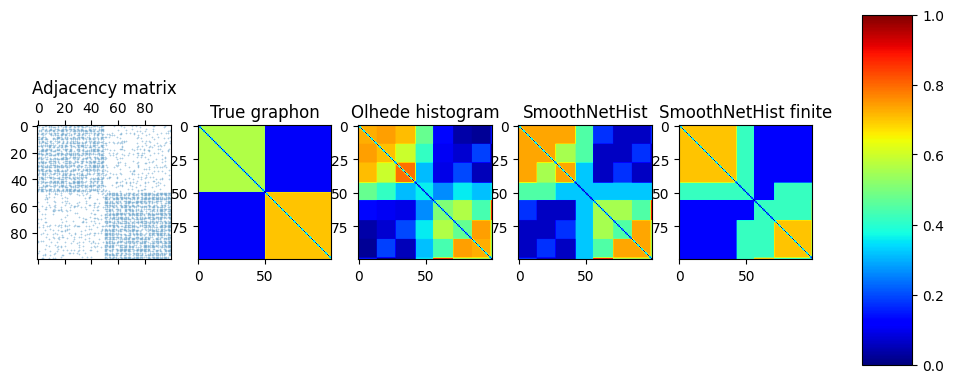

In [14]:
fig, ax = plt.subplots(1, 5, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(my_est._first_fit_graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im3 = ax[3].imshow(my_est.graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im4 = ax[4].imshow(finite_est[0].get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
ax[3].set_title("SmoothNetHist")
ax[4].set_title("SmoothNetHist finite")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.colorbar(im3, cax=cbar_ax)
plt.colorbar(im4, cax=cbar_ax)
plt.show()

In [15]:
norm_smoothnet_mse_true = MseProbaEdge(n_nodes=n)(graphon, finite_est[0])
norm_smoothnet_mae_true = MaeProbaEdge(n_nodes=n)(graphon, finite_est[0])
norm_smoothnet_auc_true = AUCEdge(n_nodes=n)(adjacency_matrix, finite_est[0].get_edge_probabilities(n,False,True))
norm_smoothnet_auprc_true = AUPRCEdge(n_nodes=n)(adjacency_matrix, finite_est[0].get_edge_probabilities(n,False,True))

print("MSE Olhede vs SmoothNetHist vs Corrected:", norm_olhede_mse, norm_smoothnet_mse, norm_smoothnet_mse_true)
print("MAE Olhede vs SmoothNetHist vs Corrected:", norm_olhede_mae, norm_smoothnet_mae, norm_smoothnet_mae_true)
print("AUC Olhede vs SmoothNetHist vs Corrected:", norm_olhede_auc, norm_smoothnet_auc, norm_smoothnet_auc_true)
print("AUPRC Olhede vs SmoothNetHist vs Corrected:", norm_olhede_auprc, norm_smoothnet_auprc, norm_smoothnet_auprc_true)

MSE Olhede vs SmoothNetHist vs Corrected: 0.029630849703642822 0.02855307064754858 0.03276672174852709
MAE Olhede vs SmoothNetHist vs Corrected: 0.1360940333184312 0.13492934762140063 0.12023170546799998
AUC Olhede vs SmoothNetHist vs Corrected: 0.742288047983753 0.7424548740031043 0.7217778922512226
AUPRC Olhede vs SmoothNetHist vs Corrected: 0.5576112908614713 0.5500766272159605 0.5242108336288342


# Other plots for paper

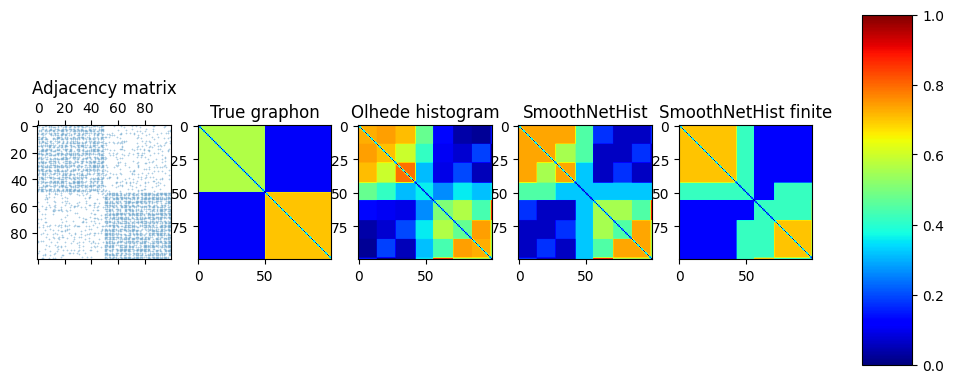

In [16]:
fig, ax = plt.subplots(1, 5, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(my_est._first_fit_graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im3 = ax[3].imshow(my_est.graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im4 = ax[4].imshow(finite_est[0].get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
ax[3].set_title("SmoothNetHist")
ax[4].set_title("SmoothNetHist finite")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.colorbar(im3, cax=cbar_ax)
plt.colorbar(im4, cax=cbar_ax)
plt.show()

# Polblog

In [17]:
import io
from zipfile import ZipFile
import requests
import pandas as pd
import networkx as nx

url =  "https://networks.skewed.de/net/polblogs/files/polblogs.csv.zip"
response = requests.get(url, stream=True)
with ZipFile(io.BytesIO(response.content)) as myzip:
   with myzip.open(myzip.namelist()[0]) as myfile:
      df = pd.read_csv(myfile)
   with myzip.open(myzip.namelist()[1]) as myfile:
      df2 = pd.read_csv(myfile)

df.columns = ["source", "target"]
df2.columns = [s.replace(" ","") for s in df2.columns]
z = df2["value"].values
#df2.columns = ["value"] # 0 for liberals, 1 for conservative
A = nx.to_numpy_array(nx.from_pandas_edgelist(df, "source", "target"))
# we remove the diagonal to avoid self-loops
A -= np.diag(np.diag(A))

In [24]:
num_liberals = np.sum(z == 0)
num_conservatives = np.sum(z == 1)
print(num_conservatives)
print(num_liberals)

732
758


C:\Users\arthu\AppData\Local\Temp\ipykernel_17800\3969485779.py:17: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  reordered_A = nx.adjacency_matrix(G, nodelist=nodes_0_sorted + nodes_1_sorted).toarray()


(<Figure size 500x500 with 1 Axes>, <AxesSubplot:>)

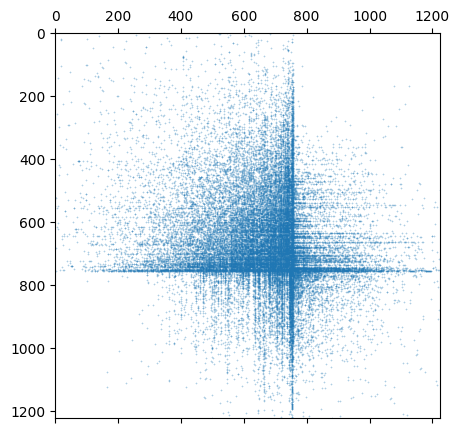

In [23]:
import networkx as nx

# Create a graph from the adjacency matrix
G = nx.from_numpy_array(A)

# Compute the degrees of the nodes
degrees = dict(G.degree())

# Sort nodes by increasing degrees within each membership group
nodes_0 = [node for node in G.nodes() if z[node] == 0]
nodes_1 = [node for node in G.nodes() if z[node] == 1]

nodes_0_sorted = sorted(nodes_0, key=lambda node: degrees[node])
nodes_1_sorted = sorted(nodes_1, key=lambda node: degrees[node], reverse=True)

# Create the reordered adjacency matrix
reordered_A = nx.adjacency_matrix(G, nodelist=nodes_0_sorted + nodes_1_sorted).toarray()

spy(reordered_A)


In [26]:
reordered_A.shape

(1224, 1224)

In [28]:
est = SmoothNetHist()
est.fit(reordered_A)
first_hist_olhede = est._first_approximate_graphon_from_adjacency(adjacencyMatrix= reordered_A)

In [33]:
print(est.get_ratio_par())
print("Number of unique parameters in SmoothNetHist:", len(np.unique(est.graphon.get_graphon())))
print("Number of unique parameters in Olhede:", len(np.unique(first_hist_olhede[0].get_graphon())))

0.19607843137254902
Number of unique parameters in SmoothNetHist: 30
Number of unique parameters in Olhede: 79


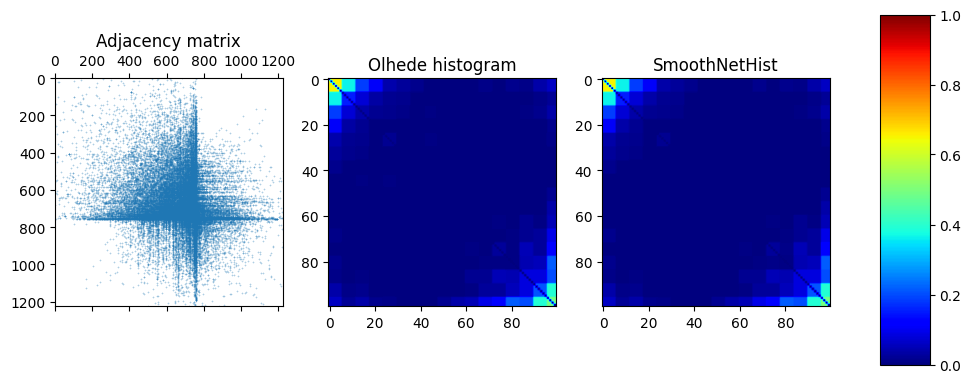

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(est._first_fit_graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(est.graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(reordered_A, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("Olhede histogram")
ax[2].set_title("SmoothNetHist")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)

plt.show()

In [36]:
est.graphon.get_graphon()

array([[2.90221112e+01, 1.63233664e+01, 8.37117197e+00, 4.76796481e+00,
        1.72092062e+00, 1.10778835e+00, 5.89418332e-01, 2.63357333e-02,
        2.63357333e-02, 8.88002555e-02, 7.98052525e-04, 5.89418332e-01,
        8.88002555e-02, 5.89418332e-01, 3.74407030e-01, 1.57116591e+00,
        2.75268267e+00],
       [1.63233664e+01, 6.96666603e+00, 3.31830240e+00, 1.57116591e+00,
        7.88002940e-01, 5.89418332e-01, 1.68716063e-01, 8.88002555e-02,
        7.98052525e-04, 7.98052525e-04, 2.63357333e-02, 8.88002555e-02,
        2.63357333e-02, 2.63357333e-02, 8.88002555e-02, 3.74407030e-01,
        9.28484235e-01],
       [8.37117197e+00, 3.31830240e+00, 1.72092062e+00, 7.88002940e-01,
        5.89418332e-01, 3.74407030e-01, 2.63357333e-02, 1.68716063e-01,
        7.98052525e-04, 7.98052525e-04, 2.63357333e-02, 8.88002555e-02,
        7.98052525e-04, 8.88002555e-02, 2.58788483e-01, 5.89418332e-01,
        1.72092062e+00],
       [4.76796481e+00, 1.57116591e+00, 7.88002940e-01, 8.880

In [41]:
graphon_polblogs = est.graphon.get_graphon()
# Get the diagonal elements
diagonal = np.diag(graphon_polblogs)

# Sort the diagonal elements in increasing order and get the sorting indices
sorting_indices = np.argsort(diagonal)

# Permute the rows and columns of the matrix based on the sorting indices
graphon_polblogs_permuted = graphon_polblogs[sorting_indices][:, sorting_indices]

print(graphon_polblogs_permuted.shape)

(17, 17)


C:\Users\arthu\AppData\Local\Temp\ipykernel_17800\3672621297.py:13: MatplotlibDeprecationWarning: Starting from Matplotlib 3.6, colorbar() will steal space from the mappable's axes, rather than from the current axes, to place the colorbar.  To silence this warning, explicitly pass the 'ax' argument to colorbar().
  plt.colorbar(orientation='vertical')


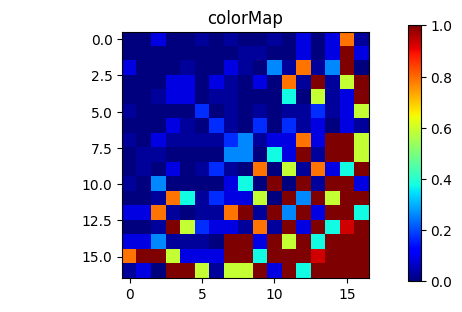

In [43]:
fig = plt.figure(figsize=(6, 3.2))

ax = fig.add_subplot(111)
ax.set_title('colorMap')
plt.imshow(graphon_polblogs_permuted, cmap='jet', vmin=0, vmax=1)
ax.set_aspect('equal')

cax = fig.add_axes([0.12, 0.1, 0.78, 0.8])
cax.get_xaxis().set_visible(False)
cax.get_yaxis().set_visible(False)
cax.patch.set_alpha(0)
cax.set_frame_on(False)
plt.colorbar(orientation='vertical')
plt.show()